In [1]:
import cv2
import numpy as np
import copy
import matplotlib.pyplot as plt 

#### 1. Подберите параметры алгоритма разрастания регионов так, чтобы был выделен весь участок газона.

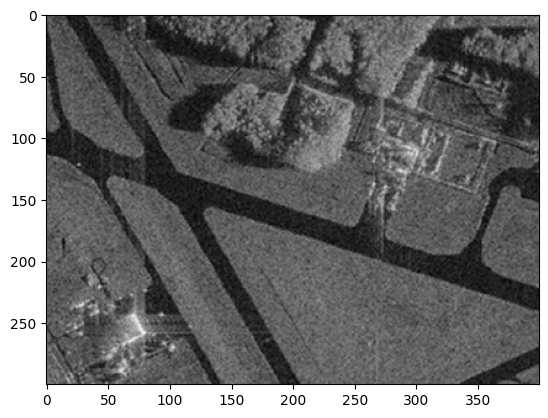

In [2]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap='gray')

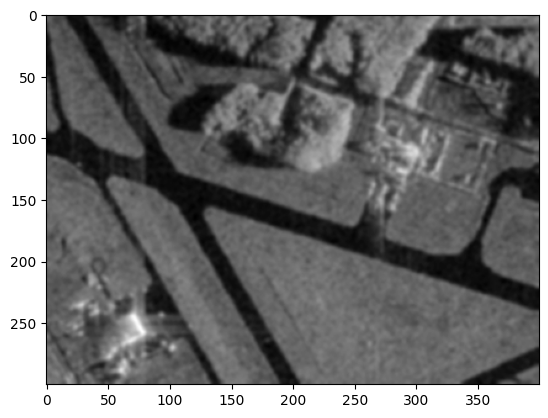

In [3]:
image_gray = cv2.GaussianBlur(image_gray, (7, 7), 0)
plt.imshow(image_gray, cmap='gray')

In [4]:
def homo_average(img, mask, point, T):
    avg_val = img[mask > 0].mean()
    if abs(avg_val - float(img[point])) <= T:
        return True
    return False


def region_growing(image, seed_point, homo_fn, r, T):
    mask = np.zeros(image.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        local_mask = np.zeros(image.shape, np.uint8)
        for i in range(r, image.shape[0] - r):
            for j in range(r, image.shape[1] - r):
                if mask[i, j] == 0 and mask[i-r:i+r+1, j-r:j+r+1].sum() > 0:
                    if homo_fn(image, mask, (i, j), T):
                        local_mask[i, j] = 1
        count = np.count_nonzero(local_mask)
        mask += local_mask
    return mask * 255

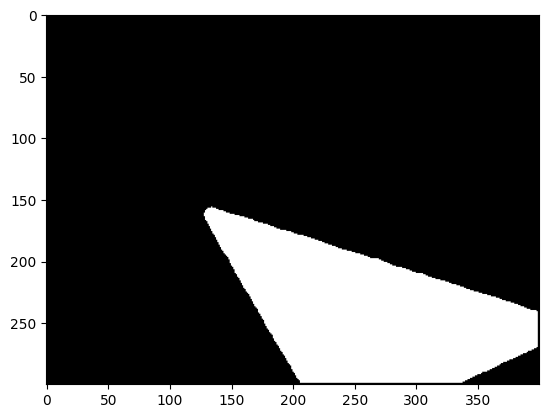

In [5]:
seed_point = (250, 250)
r=1
T=25
mask = region_growing(image_gray, seed_point, homo_average, r, T)
plt.imshow(mask, cmap='gray')

#### 2. Реализуйте вычисление критерия однородности, отличного от представленного. Сравните результаты.

In [6]:
def homo_median(img, mask, point, T):
    med_val = np.median(img[mask > 0])
    if abs(med_val - float(img[point])) <= T:
        return True
    return False

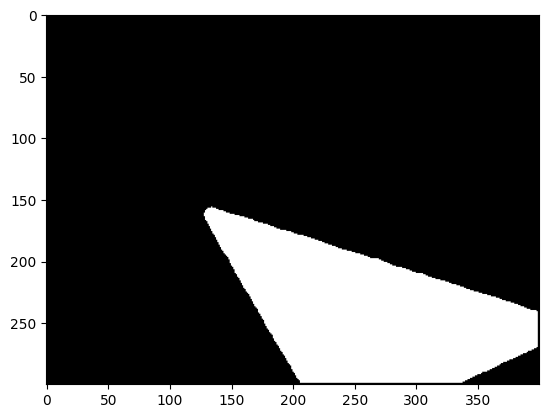

In [7]:
mask_median = region_growing(image_gray, seed_point, homo_median, r, T)
plt.imshow(mask_median, cmap='gray')

Text(0.5, 1.0, 'Median')

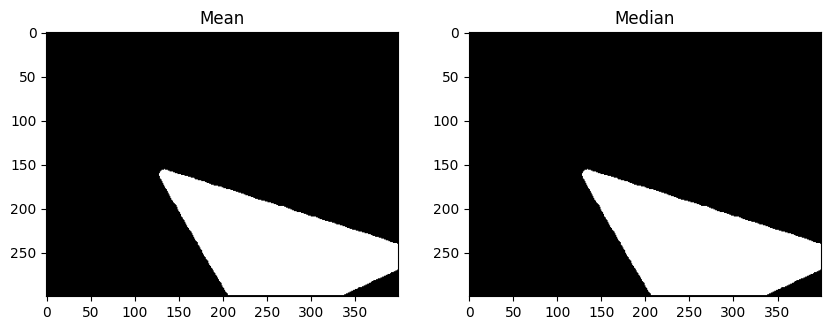

In [8]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(mask, cmap='gray')
plt.title('Mean')
plt.subplot(1, 2, 2)
plt.imshow(mask_median, cmap='gray')
plt.title('Median')

In [9]:
T1 = 15

mask_average1 = region_growing(image_gray, seed_point, homo_average, r, T1)
mask_median1 = region_growing(image_gray, seed_point, homo_median, r, T1)

Text(0.5, 1.0, 'Median, T=15')

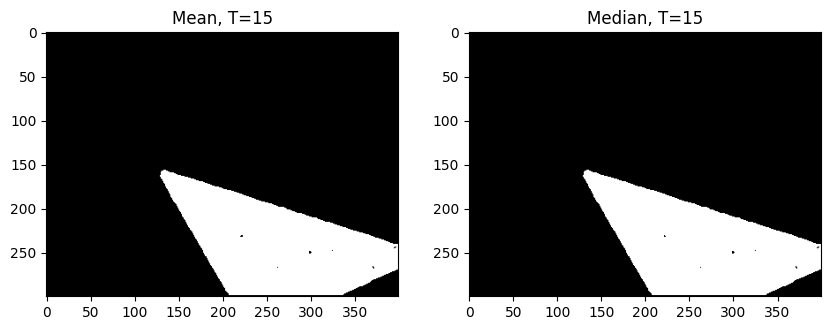

In [10]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(mask_average1, cmap='gray')
plt.title('Mean, T=15')
plt.subplot(1, 2, 2)
plt.imshow(mask_median1, cmap='gray')
plt.title('Median, T=15')

**Вывод**: можно увидеть, что алгоритм с медианой лучше выделяет участок

#### 3. Применить алгоритм сегментации watershed+distance transform для задачи подсчета пальмовых деревьев.

In [11]:
image = cv2.imread('palm_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

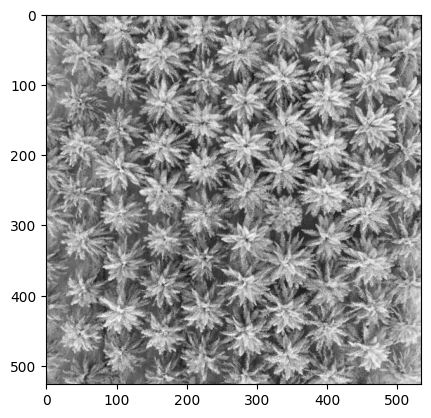

In [12]:
plt.imshow(image_gray, cmap='gray')

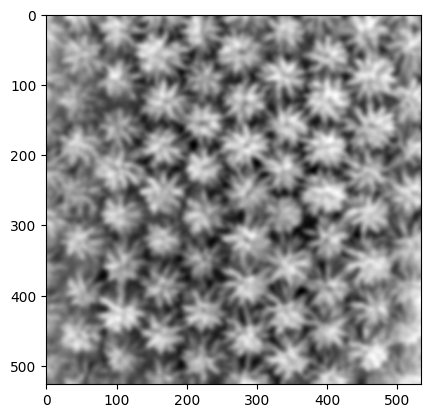

In [13]:
image_gray = cv2.GaussianBlur(image_gray, (19, 19), 0)
plt.imshow(image_gray, cmap='gray')

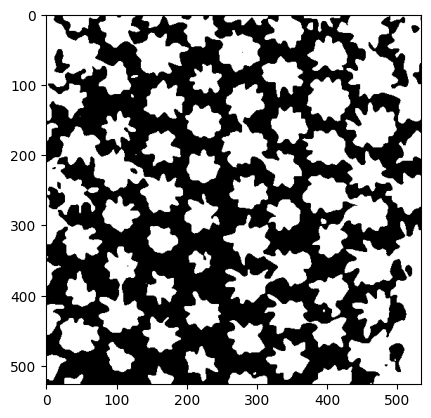

In [14]:
ret, thresh = cv2.threshold(image_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
plt.imshow(thresh, cmap='gray')

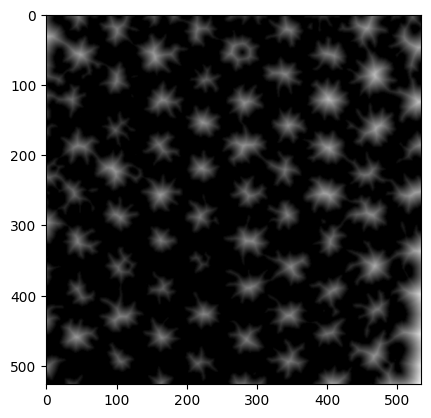

In [15]:
dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 5)
plt.imshow(dist, cmap='gray')

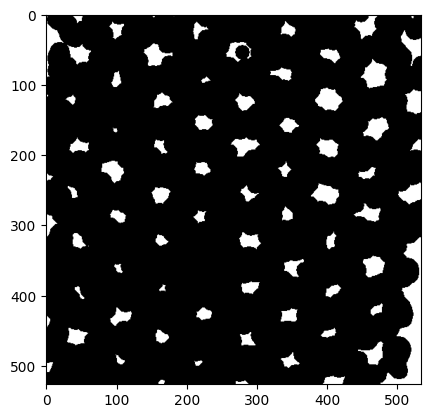

In [24]:
ret, sure_fg = cv2.threshold(dist, 0.3 * dist.max(), 255, cv2.THRESH_BINARY)
sure_fg = sure_fg.astype(np.uint8)
plt.imshow(sure_fg, cmap='gray')

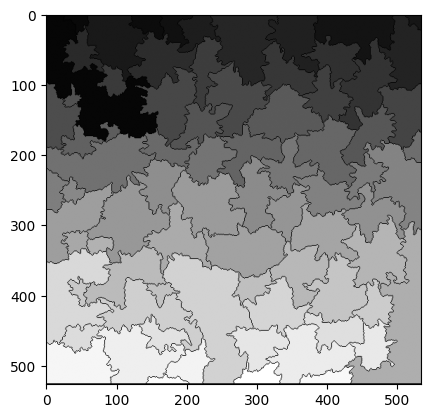

In [22]:
ret, markers = cv2.connectedComponents(sure_fg)
markers = cv2.watershed(image, markers)

label = np.unique(markers)
count = np.count_nonzero(label > 1)

image[markers == -1] = [0, 0, 255]
plt.imshow(markers, cmap='gray')

In [20]:
print(f'{count} palms on the picture')

77 palms on the picture


Количество выделенных пальм: 78


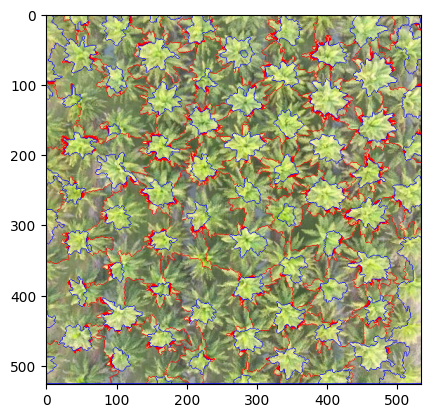

In [27]:
ret, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[(thresh > 0) & (sure_fg == 0)] = 0
markers = cv2.watershed(image, markers)

label = np.unique(markers)
count = np.count_nonzero(label > 1)
print('Количество выделенных пальм:', count)

image[markers == -1] = [255, 0, 0]
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))